In [1]:
%% MIT 18.03 Lecture 15: Operators, Undamped Resonance & Complex Gain
% Description: Simulates pure resonance dynamics using Control System Toolbox:
%              1) System modeling via transfer function G(s) = 1/p(s).
%              2) Pure resonance: x'' + 4x = cos(2t), producing secular growth x_p = (t/4)*sin(2t).
%              3) Pole-zero map (pzplot) and Bode frequency response showing resonant peak.
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, lsim, pzplot, bode).
%
% % MBD Concept Mapping: Encapsulates operator p(D) as continuous LTI plant G(s) = 1/p(s).
% %                      Demonstrates secular growth when input matches imaginary axis pole.
% %                      Compares undamped infinite peak against damped bounded frequency response.


clear; clc; close all;


%% 1. LTI System Modeling via Control System Toolbox
% Lecture Benchmark: x'' + 4x = cos(2t) -> p(s) = s^2 + 4
% Plant Transfer Function: G_undamped(s) = 1 / (s^2 + 4)
num = 1;
den_undamped = [1, 0, 4];
G_undamped = tf(num, den_undamped);


% Contrast Plant with small physical damping: G_damped(s) = 1 / (s^2 + 0.2s + 4)
den_damped = [1, 0.2, 4];
G_damped = tf(num, den_damped);


fprintf('=== Control System Toolbox Plant Definitions ===\n');

=== Control System Toolbox Plant Definitions ===

In [2]:
fprintf('Undamped Plant G(s) : \n');

Undamped Plant G(s) :

In [3]:
display(G_undamped);

G_undamped =
 
     1
  -------
  s^2 + 4
 
Continuous-time transfer function.
Model Properties

In [4]:
fprintf('Damped Plant G_d(s) : \n');

Damped Plant G_d(s) :

In [5]:
display(G_damped);

G_damped =
 
         1
  ---------------
  s^2 + 0.2 s + 4
 
Continuous-time transfer function.
Model Properties

In [6]:
fprintf('Undamped Poles      : \n');

Undamped Poles      :

In [7]:
disp(pole(G_undamped));

   0.0000 + 2.0000i
   0.0000 - 2.0000i

In [8]:
fprintf('================================================\n\n');


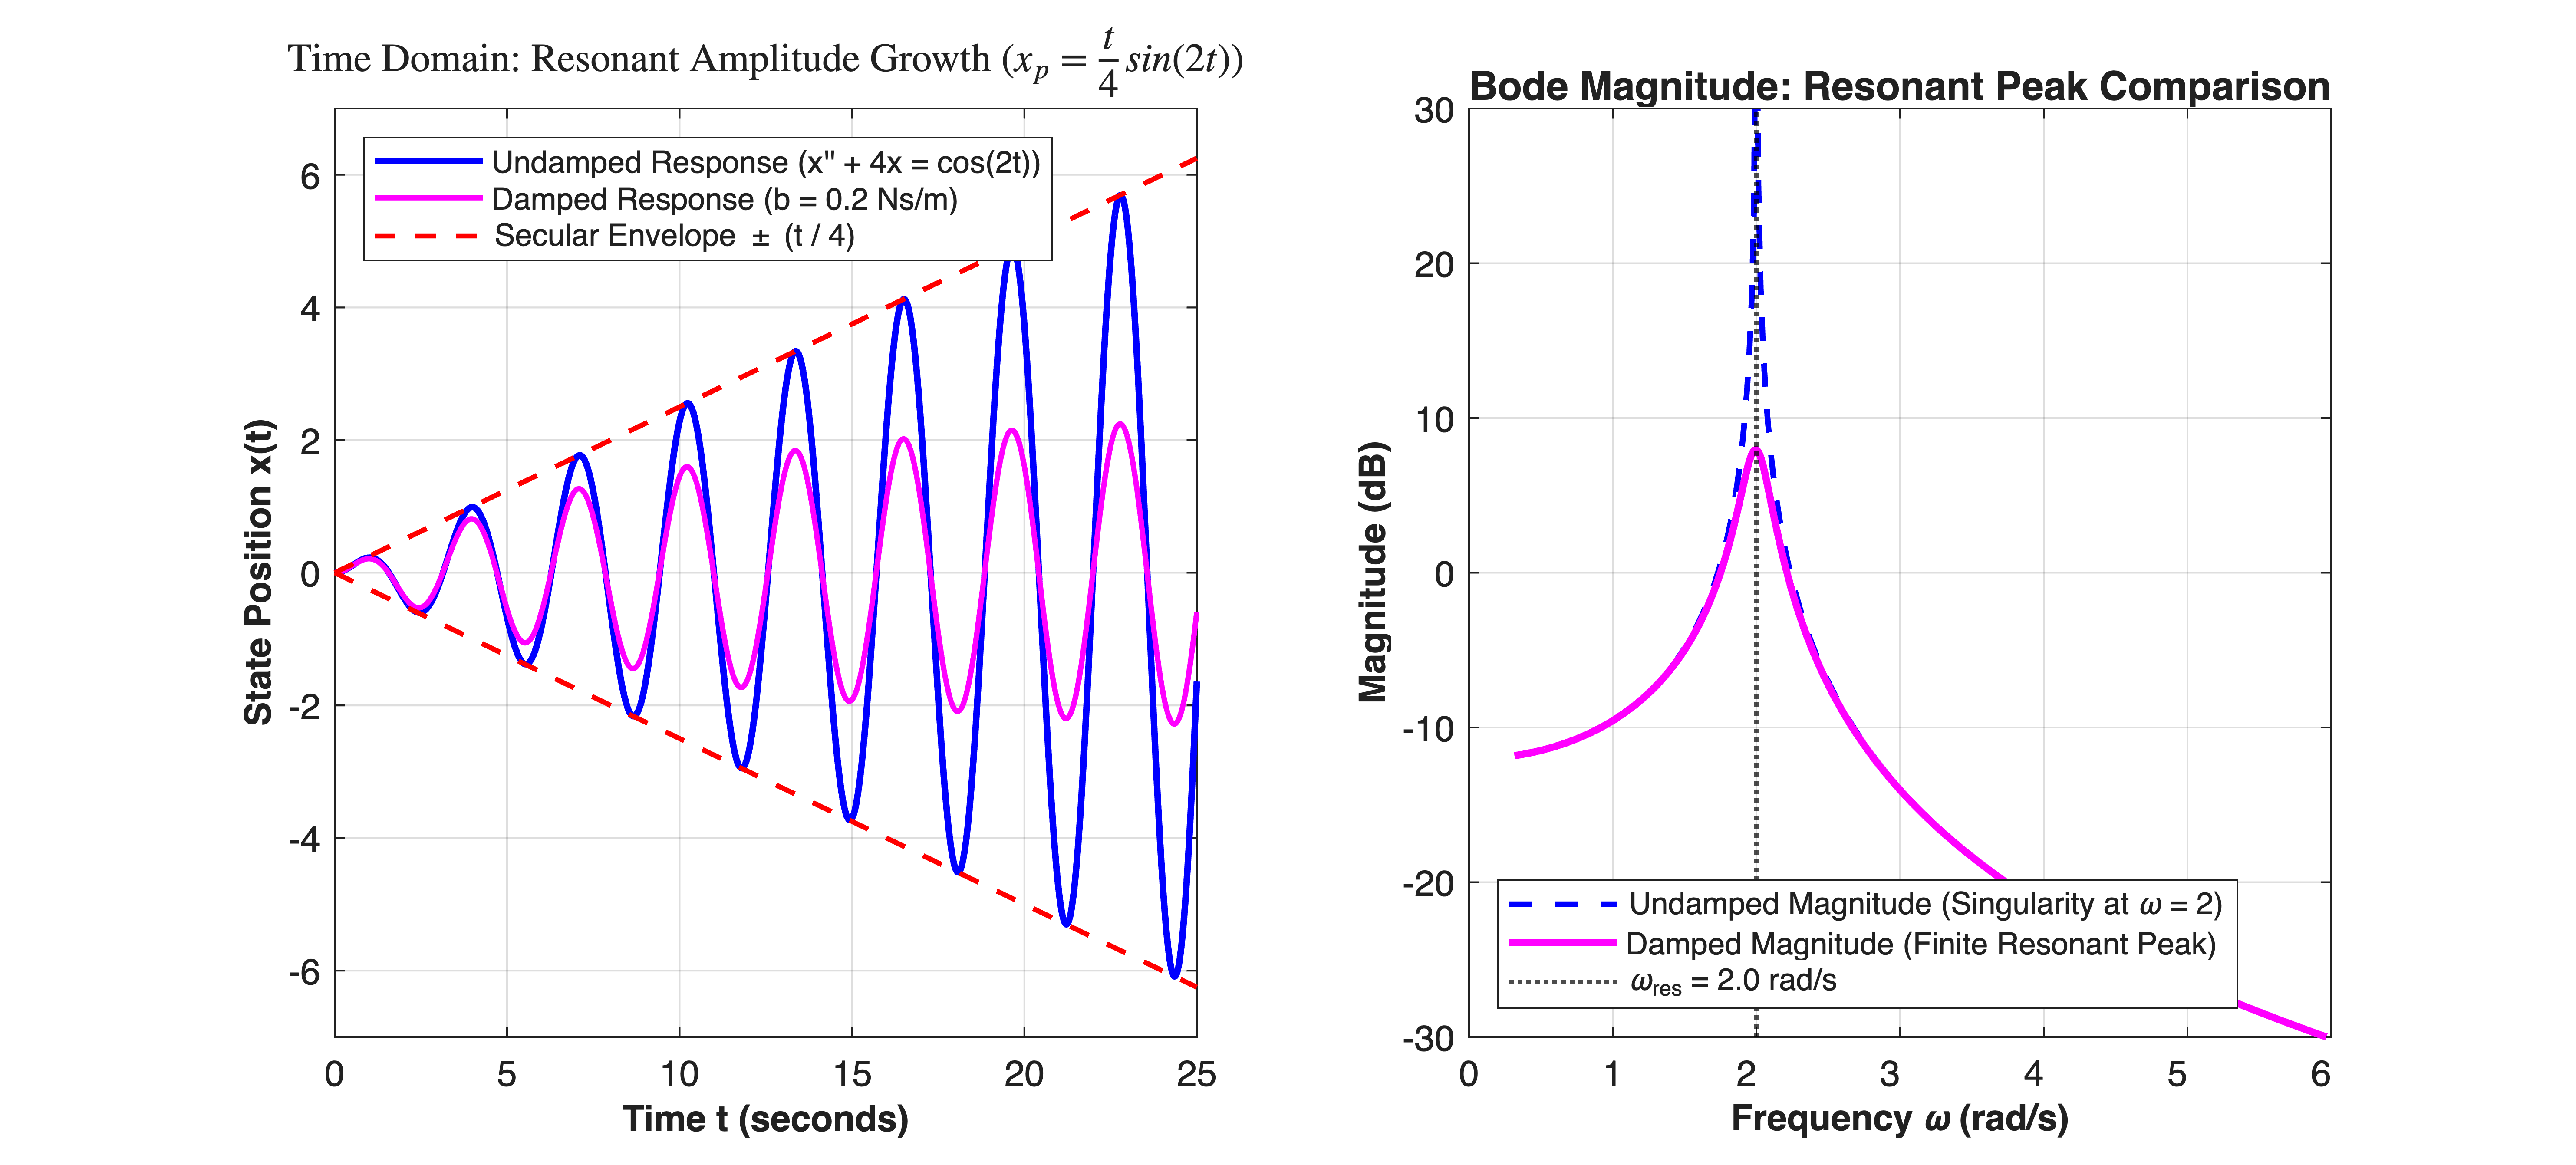

In [9]:


%% 2. Time-Domain Simulation under Resonant Forcing: u(t) = cos(2t)
t_span = [0, 25]; % 25 seconds simulation horizon
t_sim = linspace(t_span(1), t_span(2), 1200);
w_res = 2.0;      % Resonant circular frequency matching pole s = +/- 2i
u_input = cos(w_res * t_sim);


% Simulate linear time-invariant system response using lsim
[y_undamped, ~] = lsim(G_undamped, u_input, t_sim);
[y_damped, ~]   = lsim(G_damped,   u_input, t_sim);


% Analytical Resonant Secular Envelope: +/- (t / 4)
envelope_pos =  0.25 * t_sim;
envelope_neg = -0.25 * t_sim;


%% 3. Figure 1: Time-Domain Dynamic Response (Secular Growth vs. Damped Bound)
figure('Color', [1 1 1], 'Position', [100, 100, 1150, 520]);


subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_sim, y_undamped, 'b-', 'LineWidth', 1.8, ...
    'DisplayName', 'Undamped Response (x'''' + 4x = cos(2t))');
plot(t_sim, y_damped, 'm-', 'LineWidth', 1.5, ...
    'DisplayName', 'Damped Response (b = 0.2 Ns/m)');
plot(t_sim, envelope_pos, 'r--', 'LineWidth', 1.4, ...
    'DisplayName', 'Secular Envelope \pm (t / 4)');
plot(t_sim, envelope_neg, 'r--', 'LineWidth', 1.4, 'HandleVisibility', 'off');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Position x(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Time Domain: Resonant Amplitude Growth $(x_p = \frac{t}{4}sin(2t))$', ...
    'FontSize', 11, 'FontWeight', 'bold', 'Interpreter','latex');
legend('Location', 'northwest', 'FontSize', 8.5);
xlim([0, 25]);
ylim([-7, 7]);


%% 4. Figure 2: Pole-Zero Map & Frequency Response Analysis
subplot(1, 2, 2);
hold on; grid on; box on;


% Frequency vector for Bode calculation
w_sweep = logspace(-0.5, 1.2, 500);
[mag_undamped, ~] = bode(G_undamped, w_sweep);
[mag_damped, ~]   = bode(G_damped,   w_sweep);


mag_undamped_dB = 20 * log10(squeeze(mag_undamped));
mag_damped_dB   = 20 * log10(squeeze(mag_damped));


semilogx(w_sweep, mag_undamped_dB, 'b--', 'LineWidth', 1.6, ...
    'DisplayName', 'Undamped Magnitude (Singularity at \omega = 2)');
semilogx(w_sweep, mag_damped_dB, 'm-', 'LineWidth', 2.0, ...
    'DisplayName', 'Damped Magnitude (Finite Resonant Peak)');
xline(w_res, 'k:', 'LineWidth', 1.2, 'DisplayName', '\omega_{res} = 2.0 rad/s');


xlabel('Frequency \omega (rad/s)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Magnitude (dB)', 'FontSize', 10, 'FontWeight', 'bold');
title('Bode Magnitude: Resonant Peak Comparison', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'southwest', 'FontSize', 8.5);
ylim([-30, 30]);